### About this assignment
This assignment is devoted to solving regression problem on taxi ride dataset, with features analysis and finding good features for prediction. Also here we meet with the libraries `seaborn` and `sklearn`.

In the assignment we will use `folium` library. Install it if necessary.

In [1]:
# !pip install folium

In [2]:
import folium

m = folium.Map(location=(53.0833684, 8.8137641), zoom_start=12)

m

If everything is OK then you should see a map of Bremen.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set(style="darkgrid")

np.random.seed(0)

## Part 0. Data preparation (1 pts)

**Task 1 (1 pts)**. We are going to work with data from the competition [New York City Taxi Trip Duration](https://www.kaggle.com/c/nyc-taxi-trip-duration/overview), where one should predict taxi ride duration time. Download the training set from this competition and load it:

In [4]:

file_path = "nyc-taxi-trip-duration/train.csv"   # change this if it's in another folder

# Load dataset
df = pd.read_csv(file_path)

# Basic sanity checks
print("Shape:", df.shape)
print("\nColumns:\n", df.columns)
print("\nFirst rows:")
print(df.head())

# Optional: check data types and missing values
print("\nInfo:")
print(df.info())

Shape: (1458644, 11)

Columns:
 Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration'],
      dtype='str')

First rows:
          id  vendor_id      pickup_datetime     dropoff_datetime  \
0  id2875421          2  2016-03-14 17:24:55  2016-03-14 17:32:30   
1  id2377394          1  2016-06-12 00:43:35  2016-06-12 00:54:38   
2  id3858529          2  2016-01-19 11:35:24  2016-01-19 12:10:48   
3  id3504673          2  2016-04-06 19:32:31  2016-04-06 19:39:40   
4  id2181028          2  2016-03-26 13:30:55  2016-03-26 13:38:10   

   passenger_count  pickup_longitude  pickup_latitude  dropoff_longitude  \
0                1        -73.982155        40.767937         -73.964630   
1                1        -73.980415        40.738564         -73.999481   
2                1        -73.979027        40.763939         -74.00

Pay attention to the columns `pickup_datetime` and `dropoff_datetime`. `dropoff_datetime` was added by organizers only to the training set. So this column can't be used for prediction, let's delete it. In `pickup_datetime` you can find date and time of ride start. For convenience let's transform these dates to `datetime`-objects

In [5]:
# 1. Drop leakage column
df = df.drop(columns=["dropoff_datetime"])

# 2. Convert pickup_datetime to datetime format
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

# 3. Basic check
print(df["pickup_datetime"].dtype)
print(df.head())

df['trip_duration']

datetime64[us]
          id  vendor_id     pickup_datetime  passenger_count  \
0  id2875421          2 2016-03-14 17:24:55                1   
1  id2377394          1 2016-06-12 00:43:35                1   
2  id3858529          2 2016-01-19 11:35:24                1   
3  id3504673          2 2016-04-06 19:32:31                1   
4  id2181028          2 2016-03-26 13:30:55                1   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.982155        40.767937         -73.964630         40.765602   
1        -73.980415        40.738564         -73.999481         40.731152   
2        -73.979027        40.763939         -74.005333         40.710087   
3        -74.010040        40.719971         -74.012268         40.706718   
4        -73.973053        40.793209         -73.972923         40.782520   

  store_and_fwd_flag  trip_duration  
0                  N            455  
1                  N            663  
2                  N   

0           455
1           663
2          2124
3           429
4           435
           ... 
1458639     778
1458640     655
1458641     764
1458642     373
1458643     198
Name: trip_duration, Length: 1458644, dtype: int64

In the column `trip_duration` you can find target values for prediction. Let's look at target distribution on the training set. Plot the histogram for this:

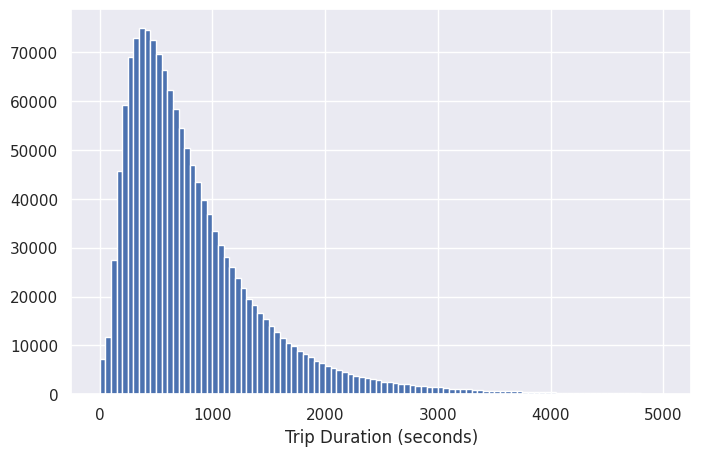

In [6]:
plt.figure(figsize=(8,5))
plt.hist(df["trip_duration"], bins=100, range=(0, 5000))
plt.xlabel("Trip Duration (seconds)")
plt.show()

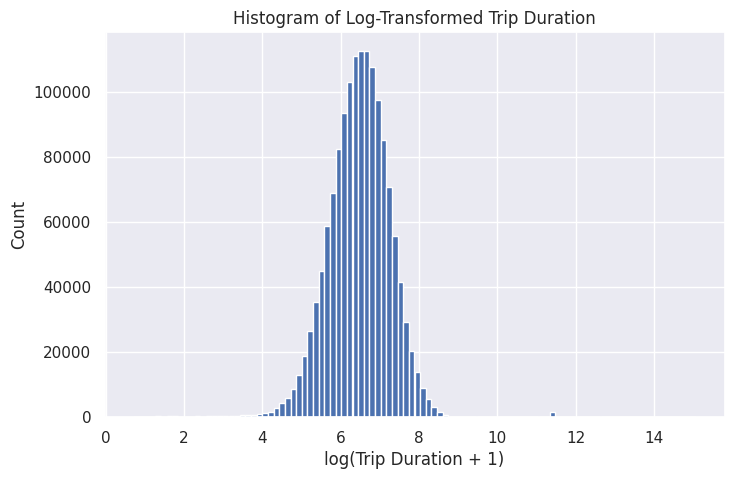

In [7]:
plt.figure(figsize=(8,5))
plt.hist(np.log1p(df["trip_duration"]), bins=100)
plt.xlabel("log(Trip Duration + 1)")
plt.ylabel("Count")
plt.title("Histogram of Log-Transformed Trip Duration")
plt.show()

**Question**: What can be said about target variable based on this histogram?

Trip duration peaks around 400 seconds. The distribution is strongly right-skewed, with most trips concentrated below roughly 1000 seconds and a long tail extending toward much larger durations.

After applying a log transformation, the distribution becomes much more symmetric and closer to a bell-shaped curve.

In the competition RMSLE is used as a quality metric:
$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{N}\sum_{i=1}^{N} \big(\log{(y_i + 1)} - \log{(a(x_i) + 1)}\big)^2}$$

**Question**: How do you think, why the organizers used RMSLE and not RMSE?

The original scale (RMSE) would over-penalize large trips and allow extreme values to dominate the metric. RMSLE effectively measures error on the logarithmic scale, which reduces the influence of outliers, emphasizes relative (percentage) errors rather than absolute errors, and aligns better with the statistical structure of the transformed target.

Standard linear regression model in `sklearn` is usually trained by minimizing MSE and not RMSLE. Let's use the following trick: we will predict not the original target, but its logarithm $\hat{y}_i = \log{(y_i + 1)}$. Then the prediction of the original target can be found by $a(x_i) = \exp(\hat{a}(x_i)) - 1$, where $\hat{a}(x_i)$ is prediction from the model that is trained on the modified target $\hat{y}_i$.

So we transform the RMSLE optimization problem to standard MSE optimization. Moreover, taking the logarithm gives us additional useful property. To see it let's add to the training set the column  `log_trip_duration` (use the function `np.log1p`) and plot the histogram of modified target. Delete the column with the old target.

In [8]:
df["log_trip_duration"] = np.log1p(df["trip_duration"])

In order to start with something, let's compute the metric value for constant prediction:

In [9]:
def rmsle(log1p_y_true, log1p_y_pred): 
    log1p_y_true = np.array(log1p_y_true)
    log1p_y_pred = np.array(log1p_y_pred)

    return np.sqrt(np.mean((log1p_y_true - log1p_y_pred) ** 2))

c = df["log_trip_duration"].mean()

y_true = df["log_trip_duration"]
y_pred = np.full_like(y_true, c)

rmsle_best_const = rmsle(y_true, y_pred)

print(rmsle_best_const)
assert np.allclose(rmsle_best_const, 0.79575, 1e-4)

0.7957592365411507


## Part 1. Analyzing `pickup_datetime` (2 pts)

**Task 2 (0.25 pts)**. Let's look at a distribution of number of rides for each day of the year. Plot the dependence between number of rides and day number in a year (for example, you may use `sns.countplot`):

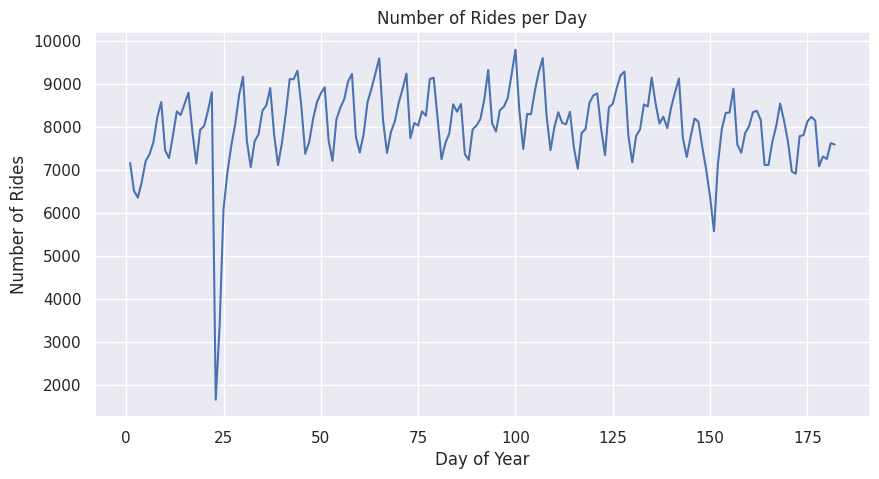

In [10]:
rides_per_day = df.groupby(df["pickup_datetime"].dt.dayofyear).size()
plt.figure(figsize=(10,5))
plt.plot(rides_per_day.index, rides_per_day.values)
plt.xlabel("Day of Year")
plt.ylabel("Number of Rides")
plt.title("Number of Rides per Day")
plt.show()

**Question**: As you probably noted on the plot there are 2 periods with too small number of rides. Find out what happened in New York City in the corresponding dates.

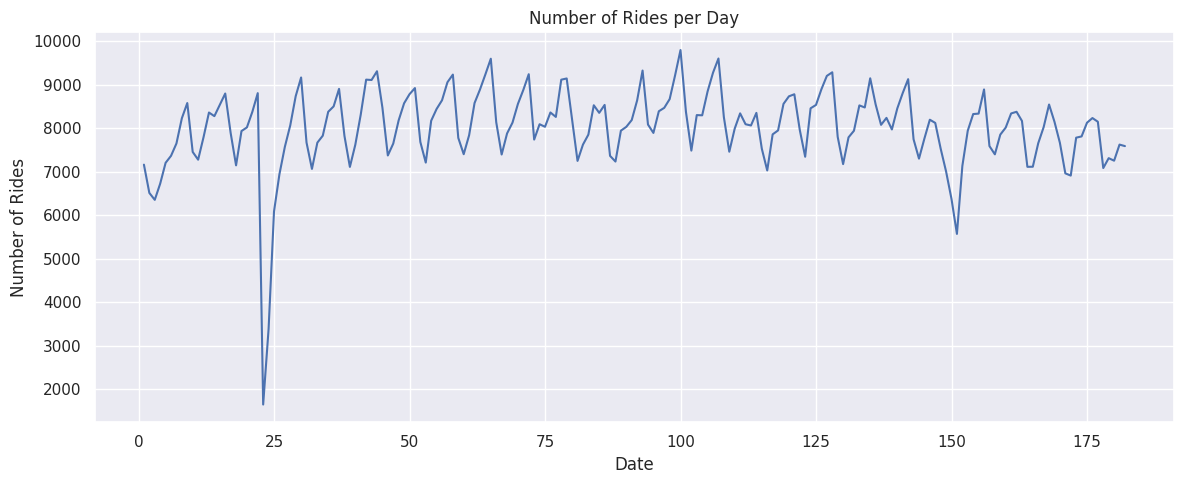

In [11]:
rides_per_day = df.groupby(df["pickup_datetime"].dt.dayofyear).size()

plt.figure(figsize=(12,5))
sns.lineplot(
    x=rides_per_day.index,
    y=rides_per_day.values
)

plt.xlabel("Date")
plt.ylabel("Number of Rides")
plt.title("Number of Rides per Day")
plt.tight_layout()
plt.show()

New York City experienced a major winter storm/blizzard in late January 2016, which dropped record-breaking snowfall levels around January 22–24. For example, at Central Park over 27 inches of snow fell on January 23, one of the highest single-day totals on record for the city. This caused travel disruptions, plowed-strewn streets, and reduced mobility.

May 30 is the U.S. Memorial Day weekend, a federal holiday (observed the last Monday in May). Holidays and long weekends often reduce commuting demand and change travel patterns.



Plot number of rides w.r.t. day of a week and hours of a day (use `sns.relplot`):

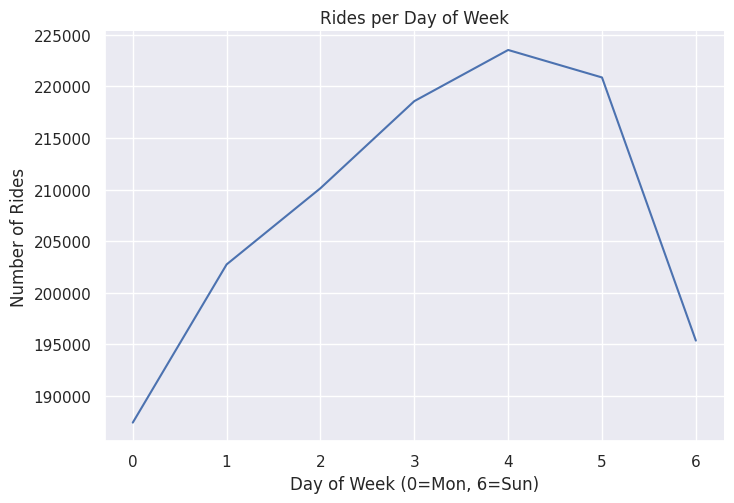

In [12]:
rides_per_weekday = (
    df.groupby(df["pickup_datetime"].dt.weekday)
      .size()
      .reset_index(name="ride_count")
)

rides_per_weekday.columns = ["weekday", "ride_count"]

sns.relplot(
    data=rides_per_weekday,
    x="weekday",
    y="ride_count",
    kind="line",
    height=5,
    aspect=1.5
)

plt.xlabel("Day of Week (0=Mon, 6=Sun)")
plt.ylabel("Number of Rides")
plt.title("Rides per Day of Week")
plt.show()

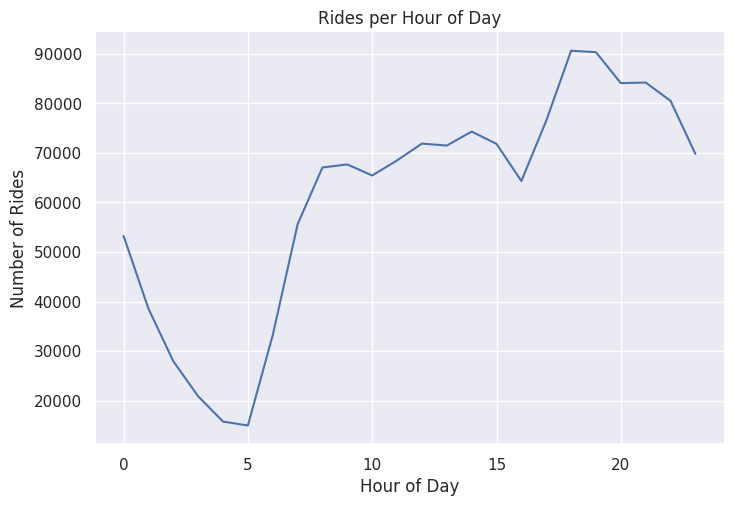

In [13]:
rides_per_hour = (
    df.groupby(df["pickup_datetime"].dt.hour)
      .size()
      .reset_index(name="ride_count")
)

rides_per_hour.columns = ["hour", "ride_count"]

sns.relplot(
    data=rides_per_hour,
    x="hour",
    y="ride_count",
    kind="line",
    height=5,
    aspect=1.5
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Rides")
plt.title("Rides per Hour of Day")
plt.show()

**Task 3 (0.5 pts)**. Plot number of rides w.r.t. hours of a day for different months (different curves corresponding to different months should be given in different colors; use `hue` in `sns.relplot`). In analogous way plot number of rides w.r.t. hours of a day for different days in a week.

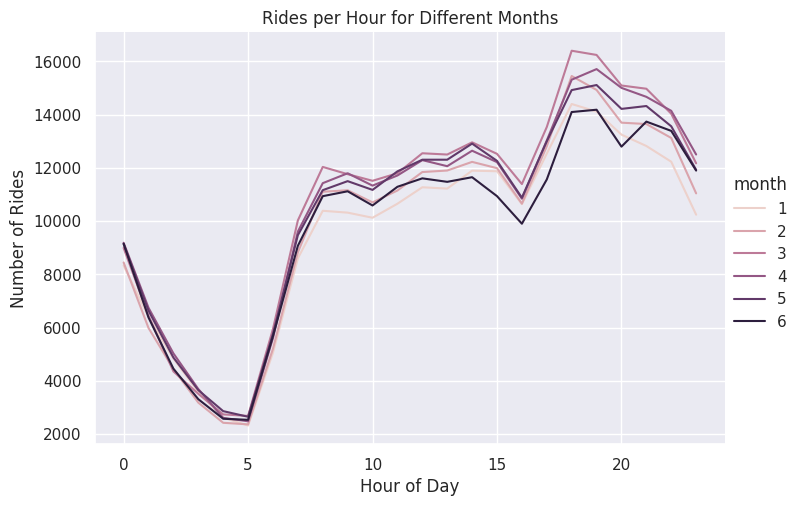

In [14]:
rides_month_hour = (
    df.groupby([
        df["pickup_datetime"].dt.month,
        df["pickup_datetime"].dt.hour
    ])
    .size()
    .rename_axis(["month", "hour"])
    .reset_index(name="ride_count")
)

rides_month_hour.columns = ["month", "hour", "ride_count"]

sns.relplot(
    data=rides_month_hour,
    x="hour",
    y="ride_count",
    hue="month",
    kind="line",
    height=5,
    aspect=1.5
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Rides")
plt.title("Rides per Hour for Different Months")
plt.show()

**Question**: What conclusions can be made based on the constructed plots? Are some days of a week differ somehow from the others? And what about hours of a day? What are the reasons for it?

For the week plot we can observe that the lowest values are held on Sunday and Monday, and it peaks around Thursday, Friday and Saturday. Sunday is low because it is typically a rest and family day in the U.S., with fewer commuters and reduced business activity compared to weekdays. On Monday, the lower values may be explained by the lack of nightlife and social events, which reduces late-evening and discretionary taxi demand. The late-week peak may be caused by increased social activity, nightlife and tourism.

About the hours of the day, the pattern is more intuitive. After midnight rides decrease as public activity drops and people go to sleep, and around 5am they gradually rise due to the start of the morning commute and work-related travel. The peak around 18:00–20:00 matches the time when people return from work or go out in the evening.

Across months, the hourly behaviour is very similar, with the lowest overall rate in June, maybe due to the start of summer.



**Task 4 (0.5 pts)**. Split dataset into train and test part in a ratio 7:3 (use `train_test_split` from `sklearn`). Using the train part plot the dependence between mean logarithm of ride duration w.r.t. day of a week. Then do the same for hour of a day and day number of a year.

In [15]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.3, random_state=42)

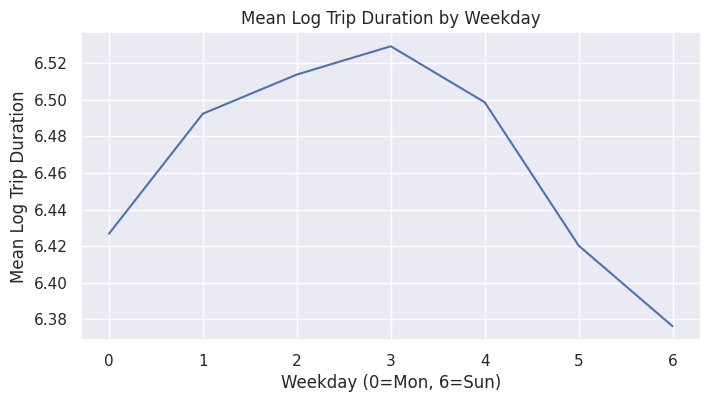

In [16]:
weekly_rides_mean_log_duration = train_df.groupby(train_df["pickup_datetime"].dt.weekday)["log_trip_duration"].mean()

plt.figure(figsize=(8,4))
sns.lineplot(
    x=weekly_rides_mean_log_duration.index,
    y=weekly_rides_mean_log_duration.values
)
plt.xlabel("Weekday (0=Mon, 6=Sun)")
plt.ylabel("Mean Log Trip Duration")
plt.title("Mean Log Trip Duration by Weekday")
plt.show()

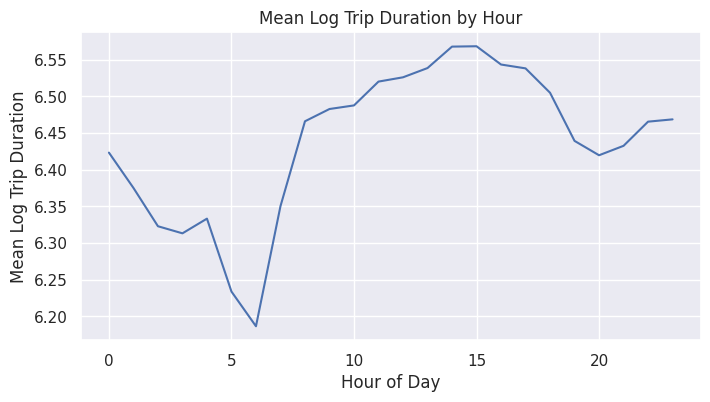

In [17]:
hourly_rides_mean_log_duration = train_df.groupby(train_df["pickup_datetime"].dt.hour)["log_trip_duration"].mean()

plt.figure(figsize=(8,4))
sns.lineplot(
    x=hourly_rides_mean_log_duration.index,
    y=hourly_rides_mean_log_duration.values
)
plt.xlabel("Hour of Day")
plt.ylabel("Mean Log Trip Duration")
plt.title("Mean Log Trip Duration by Hour")
plt.show()

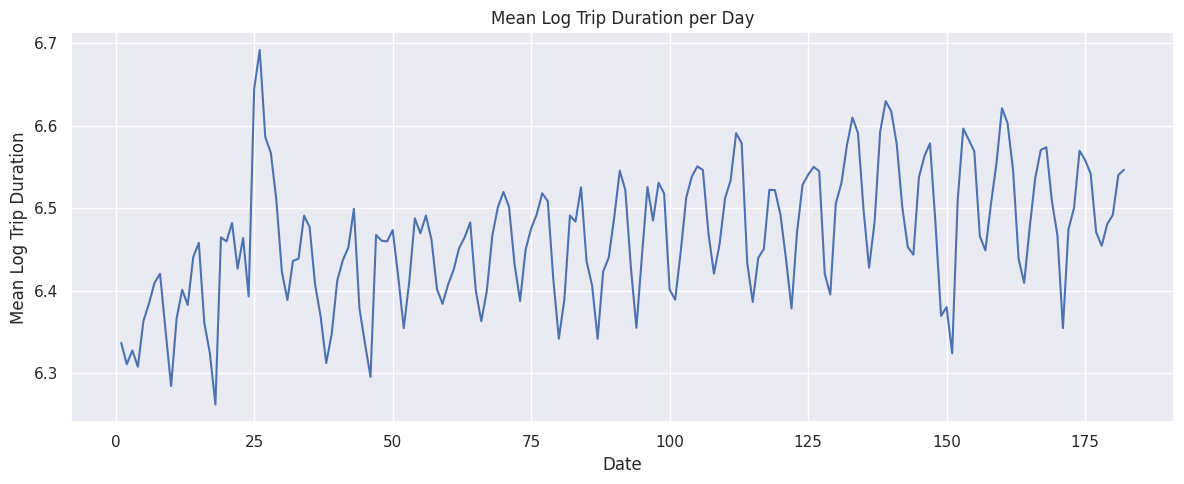

In [18]:
day_rides_mean_log_duration = train_df.groupby(train_df["pickup_datetime"].dt.dayofyear)["log_trip_duration"].mean()


plt.figure(figsize=(12,5))
sns.lineplot(
    x=day_rides_mean_log_duration.index,
    y=day_rides_mean_log_duration.values
)

plt.xlabel("Date")
plt.ylabel("Mean Log Trip Duration")
plt.title("Mean Log Trip Duration per Day")
plt.tight_layout()
plt.show()

**Question**: Are the plots of target variable w.r.t. day of a week and hour of a day similar to the analogous plots for number of rides? Why? What is happening to the mean target in those two anomalous periods? Why is that happening? Do you see any trend on a plot of dependence between `log_trip_duration` and day number of a year?

Yes, they are similar for the most part. There might be a correlation between the number of rides and the mean trip duration, as higher demand can lead to increased traffic congestion, which in turn can increase trip durations. One of the anomalous periods (late January) shows a significant spike in mean trip duration, while the number of rides dropped sharply. Likely the blizzard reduced traffic but also obstructed roads, leading longer trips despite low congestions. The second anomalous period (late May) shows a dip in mean trip duration, which matches the correlation assumption. The Memorial Day weekend likely reduced commuting and traffic, leading to shorter trips on average. Other than the anomalies only cyclic spikes can be observed, which correspond to the weekly pattern of traffic and demand.

Add the following features to the dataset based on `pickup_datetime`:
1. Day of a week
2. Month
3. Hour
4. Is the period anomalous (two binary features corresponding to two anomalous periods)
5. Day number in a year

In [19]:
for dataset in [train_df, test_df]:

    # 1. Day of week (0=Mon, 6=Sun)
    dataset["weekday"] = dataset["pickup_datetime"].dt.weekday

    # 2. Month (1–12)
    dataset["month"] = dataset["pickup_datetime"].dt.month

    # 3. Hour of day (0–23)
    dataset["hour"] = dataset["pickup_datetime"].dt.hour

    # 4. Anomalous periods (blizzard & Memorial Day weekend)
    dt = dataset["pickup_datetime"]

    dataset["is_anom_jan"] = (
        (dt >= "2016-01-23") & (dt <= "2016-01-25")
    ).astype(int)

    dataset["is_anom_may"] = (
        (dt >= "2016-05-29") & (dt <= "2016-05-30")
    ).astype(int)

    # 5. Day number in year (1–366)
    dataset["day_of_year"] = dataset["pickup_datetime"].dt.dayofyear

    So, we have created a set of features.

**Question**: Which of the features _should be considered in this task_ as cathegorical, and which - as numerical? Why?

The features "weekday", "month", "day_of_year" and anomalies features are categorical, as they represent discrete categories that do not have a meaningful smooth numerical relationship. As for "hour", it can be considered as numerical with cyclical encoding, since the data changes are smooth across the 24 hours cycle, so closer hours would have more similar trip durations than hours that are far apart.

Binary anomaly features (is_anom_jan, is_anom_may) should be treated as numerical because they already represent indicator (dummy) variables in a form directly usable by linear models.

As for "day_of_year", it is more natural to treat it as categorical, since the relationship between day of year and trip duration is not smooth and is mostly dominated by weekly patters. For this reason, this feature should be considered as categorical; but this would introduce a lot of features after one-hot-encoding. As seasonal changes are already captured by "month" feature, we can consider to drop "day_of_year" from the dataset.

In [20]:
import numpy as np

for dataset in [train_df, test_df]:
    dataset["hour_sin"] = np.sin(2 * np.pi * dataset["hour"] / 24)
    dataset["hour_cos"] = np.cos(2 * np.pi * dataset["hour"] / 24)
    dataset.drop(columns=["hour"], inplace=True)

**Task 5 (0.75 pts)**. Fit `Ridge`-regression with default parameters, encoding all cathegorical features using `OneHotEncoder`. Numerical features should be normalized using `StandardScaler`. Use only features that were created in this part of the assignment.

In [21]:
feature_cols = [
    "weekday",
    "month",
    "hour_sin",
    "hour_cos",
    "is_anom_jan",
    "is_anom_may",
]

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# --- 1. Features used ONLY for Task 5 ---
cat_features_part5 = ["weekday", "month"]
num_features_part5 = ["hour_sin", "hour_cos", "is_anom_jan", "is_anom_may"]

feature_cols_part5 = cat_features_part5 + num_features_part5

X_train = train_df[feature_cols_part5]
y_train = train_df["log_trip_duration"]

X_test  = test_df[feature_cols_part5]
y_test  = test_df["log_trip_duration"]

# --- 2. Preprocessing: OHE for cats, StandardScaler for nums ---
preprocessor_part5 = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features_part5),
        ("num", StandardScaler(), num_features_part5),
    ]
)

# --- 3. Full pipeline: preprocessing + Ridge regression ---
ridge_pipeline_part5 = Pipeline(
    steps=[
        ("preprocess", preprocessor_part5),
        ("model", Ridge())  # default hyperparameters
    ]
)

# --- 4. Train ---
ridge_pipeline_part5.fit(X_train, y_train)

# --- 5. Evaluate on log target (≈ RMSLE on original scale) ---
y_pred_log = ridge_pipeline_part5.predict(X_test)

mse_log = mean_squared_error(y_test, y_pred_log)
rmse_log = np.sqrt(mse_log)
print(f"Task 5 – RMSE on log_trip_duration (≈ RMSLE): {rmse_log:.4f}")

Task 5 – RMSE on log_trip_duration (≈ RMSLE): 0.7897


## Part 2. Analyzing coordinates (3 pts)
To the current moment we have already dived into the data about pickup start date and time. Now let's look at the information about geographical coordinates of trip start and finish. Here you can find a function that plots points of trip start and finish on a real map. Examples for its usage you may find below. Please pay attention that only a small portion of data should be given to this function. Otherwise everything would work very slowly.

In [23]:
def show_circles_on_map(data, latitude_column, longitude_column, color):
    """
    The function draws map with circles on it.
    The center of the map is the mean of coordinates passed in data.
    
    data: DataFrame that contains columns latitude_column and longitude_column
    latitude_column: string, the name of column for latitude coordinates
    longitude_column: string, the name of column for longitude coordinates
    color: string, the color of circles to be drawn
    """

    location = (data[latitude_column].mean(), data[longitude_column].mean())
    m = folium.Map(location=location)

    for _, row in data.iterrows():
        folium.Circle(
            radius=100,
            location=(row[latitude_column], row[longitude_column]),
            color=color,
            fill_color=color,
            fill=True
        ).add_to(m)

    return m

In [24]:
show_circles_on_map(df.sample(1000), "pickup_latitude", "pickup_longitude", "blue")

In [25]:
show_circles_on_map(df.sample(1000), "dropoff_latitude", "dropoff_longitude", "blue")

**Question**: Which points (or point clusters) are differ from others on this map and can be useful for our problem? What are their peculiarities? Why have you chosen them?

The most significant clusters in the image are the city center and the airports JFK and La Guardia. Taxi rides from the airport could relate heavier with trips to the city center because of tourism and I think there are other factors that we could learn from this specific locations.

**Task 6 (0.75 pts)**. Ride time can be computed as a ratio of covered distance to mean speed $t = s / v_{\text{mean}}$. Hence it is quite obvious that one of the most informative feature here for target prediction would be the covered distance. We can't compute the exact covered distance for taxi ride but we can approximate it using distance between start and finish coordinate points. Here we may use `haversine` function. Compute the approximate distance for all taxi rides and add this information to the column `haversine`.

In [26]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in kilometers

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2.0) ** 2 + \
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [27]:
train_df["haversine"] = haversine(
    train_df["pickup_latitude"],
    train_df["pickup_longitude"],
    train_df["dropoff_latitude"],
    train_df["dropoff_longitude"],
)

test_df["haversine"] = haversine(
    test_df["pickup_latitude"],
    test_df["pickup_longitude"],
    test_df["dropoff_latitude"],
    test_df["dropoff_longitude"],
)

In [28]:
train_df["haversine"].describe()

count    1.021050e+06
mean     3.443973e+00
std      4.361104e+00
min      0.000000e+00
25%      1.231736e+00
50%      2.095418e+00
75%      3.879408e+00
max      1.240909e+03
Name: haversine, dtype: float64

We are predicting logarithm of trip duration and want a linear dependence between features and target variable (because we fit linear predictors). Hence we need to take a logarithm for the covered distance: $\log t = \log s - \log{v_{\text{mean}}}$. Add logarithm of the feature `haversine` to a separate column `log_haversine`:

In [29]:
train_df["log_haversine"] = np.log1p(train_df["haversine"])
test_df["log_haversine"] = np.log1p(test_df["haversine"])

Let's see that logarithm of the distance has better correlation with targets and the distance itself:

In [30]:
train_df["log_haversine"] = np.log1p(train_df["haversine"])
test_df["log_haversine"] = np.log1p(test_df["haversine"])

your_df = train_df

corr_raw = your_df["haversine"].corr(your_df["log_trip_duration"])
corr_log = your_df["log_haversine"].corr(your_df["log_trip_duration"])

print(corr_raw)
print(corr_log)

assert corr_log > corr_raw

0.5654059873890246
0.7499594955685626


**Task 7 (0.75 pts)**. Let's investigate a mean taxi speed. Estimate the mean speed for each object from the training set by dividing `haversine` on `trip_duration`, and plot the histogram of this distribution.

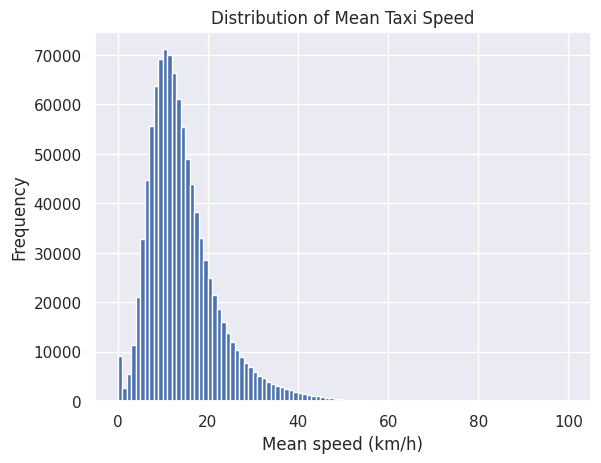

In [31]:
train_df["mean_speed_kmh"] = train_df["haversine"] / (train_df["trip_duration"] / 3600)

plt.figure()
plt.hist(train_df["mean_speed_kmh"], bins=100, range=(0, 100))
plt.xlabel("Mean speed (km/h)")
plt.ylabel("Frequency")
plt.title("Distribution of Mean Taxi Speed")
plt.show()

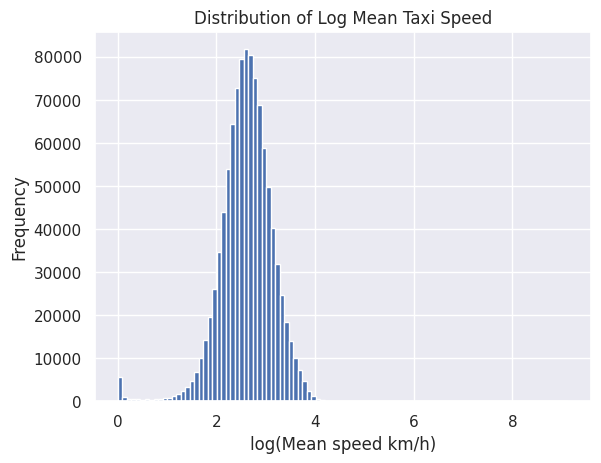

In [32]:
import numpy as np
import matplotlib.pyplot as plt

train_df["mean_speed_kmh"] = train_df["haversine"] / (train_df["trip_duration"] / 3600)

train_df["log_mean_speed"] = np.log1p(train_df["mean_speed_kmh"])

plt.figure()
plt.hist(train_df["log_mean_speed"], bins=100)
plt.xlabel("log(Mean speed km/h)")
plt.ylabel("Frequency")
plt.title("Distribution of Log Mean Taxi Speed")
plt.show()

As you may note for some objects we get very big speed values. Plot the speed histogram only for objects with reasonable speed values (for example, we may exclude objects greater than some quantile):

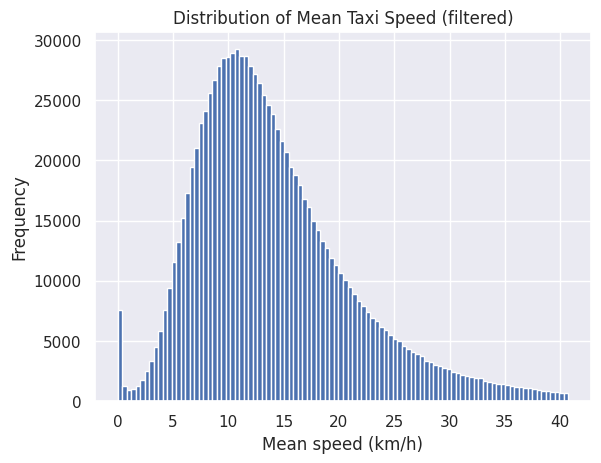

In [33]:
#Your code hereimport matplotlib.pyplot as plt

train_df["mean_speed_kmh"] = train_df["haversine"] / (train_df["trip_duration"] / 3600)

q = train_df["mean_speed_kmh"].quantile(0.99)
filtered_speed = train_df.loc[train_df["mean_speed_kmh"] <= q, "mean_speed_kmh"]

plt.figure()
plt.hist(filtered_speed, bins=100)
plt.xlabel("Mean speed (km/h)")
plt.ylabel("Frequency")
plt.title("Distribution of Mean Taxi Speed (filtered)")
plt.show()

For each pair (day of a week, hour of a day) compute speed median. Using `sns.heatmap` make a plot with axes day of a week and hour of a day and values speed median.

In [34]:
for dataset in [train_df,test_df]:
    dataset["hour"] = dataset["pickup_datetime"].dt.hour


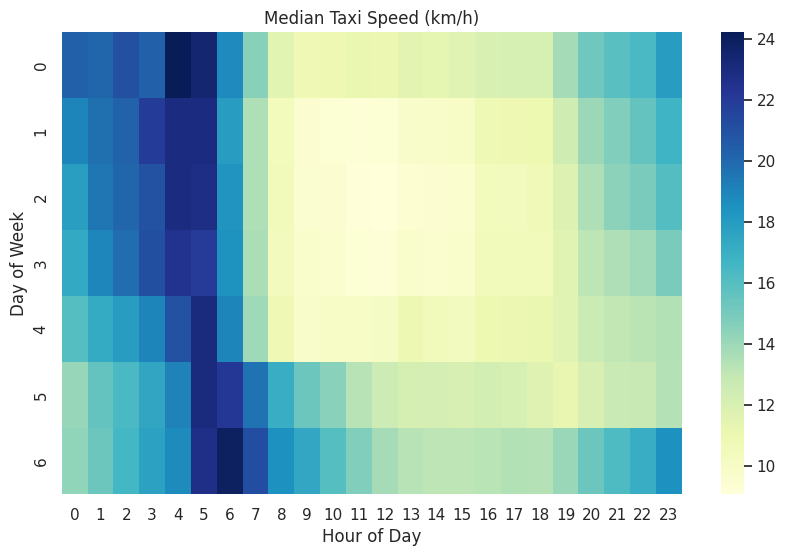

In [35]:
train_df["mean_speed_kmh"] = train_df["haversine"] / (train_df["trip_duration"] / 3600)

speed_median = (
    train_df
    .groupby(["weekday", "hour"])["mean_speed_kmh"]
    .median()
    .unstack()
)

plt.figure(figsize=(10, 6))
sns.heatmap(speed_median, cmap = "YlGnBu")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.title("Median Taxi Speed (km/h)")
plt.show()

In [36]:
train_df = train_df.drop(columns=["mean_speed_kmh"])

for dataset in [train_df,test_df]:
    dataset.drop(columns=["hour"], inplace=True)

Do not forget to delete the column with speed from the data!

**Question**: Why speed value can't be used for training?

Because it uses the target variable in its calculation.

**Question**: Look at the plot and say at what moments the speed is minimal; maximal.

Create features ''trip occurs in traffic jam'' and ''trip occurs on free roads'' (certainly it should not depend on the speed!):

In [37]:
# Traffic jam hour ranges per weekday (start inclusive, end exclusive)
TRAFFIC_JAM_RANGES = {
    0: (8, 20),
    1: (7, 21),
    2: (7, 21),
    3: (7, 23),
    4: (7, 24),
    5: (7, 24),
    6: (12, 20),
}

# Free roads hour ranges per weekday (start inclusive, end exclusive)
FREE_ROADS_RANGES = {
    0: (0, 6),
    1: (1, 5),
    2: (1, 5),
    3: (2, 5),
    4: (4, 5),
    5: (4, 7),
    6: (5, 8),
}

for dataset in [train_df, test_df]:
    hour = dataset["pickup_datetime"].dt.hour
    weekday = dataset["weekday"]

    jam_start = weekday.map({k: v[0] for k, v in TRAFFIC_JAM_RANGES.items()})
    jam_end   = weekday.map({k: v[1] for k, v in TRAFFIC_JAM_RANGES.items()})
    dataset["in_traffic_jam"] = ((hour >= jam_start) & (hour < jam_end)).astype(int)

    free_start = weekday.map({k: v[0] for k, v in FREE_ROADS_RANGES.items()})
    free_end   = weekday.map({k: v[1] for k, v in FREE_ROADS_RANGES.items()})
    dataset["on_free_roads"] = ((hour >= free_start) & (hour < free_end)).astype(int)

print(train_df[["weekday", "in_traffic_jam", "on_free_roads"]].value_counts().sort_index())


weekday  in_traffic_jam  on_free_roads
0        0               0                 37262
                         1                  9255
         1               0                 84583
1        0               0                 31830
                         1                  4335
         1               0                106074
2        0               0                 33972
                         1                  5269
         1               0                107608
3        0               0                 20953
                         1                  3542
         1               0                128471
4        0               0                 20751
                         1                  1596
         1               0                134294
5        0               0                 25453
                         1                  5844
         1               0                123202
6        0               0                 73239
                         1    

:**Task 8 (0.25 pts)**. For each of determined specific cluster of start/finish points add to the dataset two features:
- the trip was started in the specific point
- the trip was ended in the specific point

How do you think, why these features can be useful?

In [38]:
# Airport trips are structurally different — they tend to be longer, cross bridges/tunnels,
# and have fixed fare rules. Manhattan cells capture spatial demand heterogeneity: midtown
# vs. downtown vs. uptown trips have very different average durations
# ── Location definitions ──────────────────────────────────────────────────────

# Manhattan bounding box  (4 rows × 3 cols = 12 cells)
MAN_LAT_MIN, MAN_LAT_MAX = 40.700, 40.880
MAN_LON_MIN, MAN_LON_MAX = -74.020, -73.930
MAN_ROWS, MAN_COLS = 4, 3

# Airport bounding boxes
JFK_LAT = (40.620, 40.660)
JFK_LON = (-73.820, -73.750)

LGA_LAT = (40.765, 40.790)
LGA_LON = (-73.890, -73.855)


def assign_manhattan_cell(lat, lon):
    """Return Manhattan grid cell id (0..11) or -1 if outside the rectangle."""
    inside = (
        (lat >= MAN_LAT_MIN) & (lat <= MAN_LAT_MAX) &
        (lon >= MAN_LON_MIN) & (lon <= MAN_LON_MAX)
    )
    row = ((lat - MAN_LAT_MIN) / (MAN_LAT_MAX - MAN_LAT_MIN) * MAN_ROWS).astype(int).clip(0, MAN_ROWS - 1)
    col = ((lon - MAN_LON_MIN) / (MAN_LON_MAX - MAN_LON_MIN) * MAN_COLS).astype(int).clip(0, MAN_COLS - 1)
    cell = row * MAN_COLS + col          # 0 .. 11
    return np.where(inside, cell, -1)


def in_airport(lat, lon, lat_range, lon_range):
    """Return boolean Series: True when (lat, lon) falls inside the airport box."""
    return (
        (lat >= lat_range[0]) & (lat <= lat_range[1]) &
        (lon >= lon_range[0]) & (lon <= lon_range[1])
    )


# ── Add features to train and test ───────────────────────────────────────────

for dataset in [train_df, test_df]:

    # -- Manhattan grid features (one binary column per cell) --
    pickup_cell  = assign_manhattan_cell(dataset["pickup_latitude"],  dataset["pickup_longitude"])
    dropoff_cell = assign_manhattan_cell(dataset["dropoff_latitude"], dataset["dropoff_longitude"])

    for k in range(MAN_ROWS * MAN_COLS):
        dataset[f"pickup_manhattan_{k}"]  = (pickup_cell  == k).astype(int)
        dataset[f"dropoff_manhattan_{k}"] = (dropoff_cell == k).astype(int)

    # -- Airport features --
    dataset["pickup_jfk"]  = in_airport(dataset["pickup_latitude"],  dataset["pickup_longitude"],  JFK_LAT, JFK_LON).astype(int)
    dataset["dropoff_jfk"] = in_airport(dataset["dropoff_latitude"], dataset["dropoff_longitude"], JFK_LAT, JFK_LON).astype(int)

    dataset["pickup_lga"]  = in_airport(dataset["pickup_latitude"],  dataset["pickup_longitude"],  LGA_LAT, LGA_LON).astype(int)
    dataset["dropoff_lga"] = in_airport(dataset["dropoff_latitude"], dataset["dropoff_longitude"], LGA_LAT, LGA_LON).astype(int)


# ── Sanity check ─────────────────────────────────────────────────────────────
location_cols = (
    [f"pickup_manhattan_{k}"  for k in range(MAN_ROWS * MAN_COLS)] +
    [f"dropoff_manhattan_{k}" for k in range(MAN_ROWS * MAN_COLS)] +
    ["pickup_jfk", "dropoff_jfk", "pickup_lga", "dropoff_lga"]
)
print(f"New location features: {len(location_cols)}")
print("\nPickup airport counts (train):")
print(train_df[["pickup_jfk", "pickup_lga"]].sum())
print("\nDropoff airport counts (train):")
print(train_df[["dropoff_jfk", "dropoff_lga"]].sum())
print("\nManhattan pickup coverage (train):",
      train_df[[f"pickup_manhattan_{k}" for k in range(12)]].any(axis=1).sum(),
      "/ ", len(train_df))


New location features: 28

Pickup airport counts (train):
pickup_jfk    22333
pickup_lga    25916
dtype: int64

Dropoff airport counts (train):
dropoff_jfk     8785
dropoff_lga    12705
dtype: int64

Manhattan pickup coverage (train): 950696 /  1021050


For each of the constructed features make a boxplot (`sns.boxplot`) for distribution of logarithm of trip duration

For each of the constructed features make a boxplot (`sns.boxplot`) for distribution of logarithm of trip duration

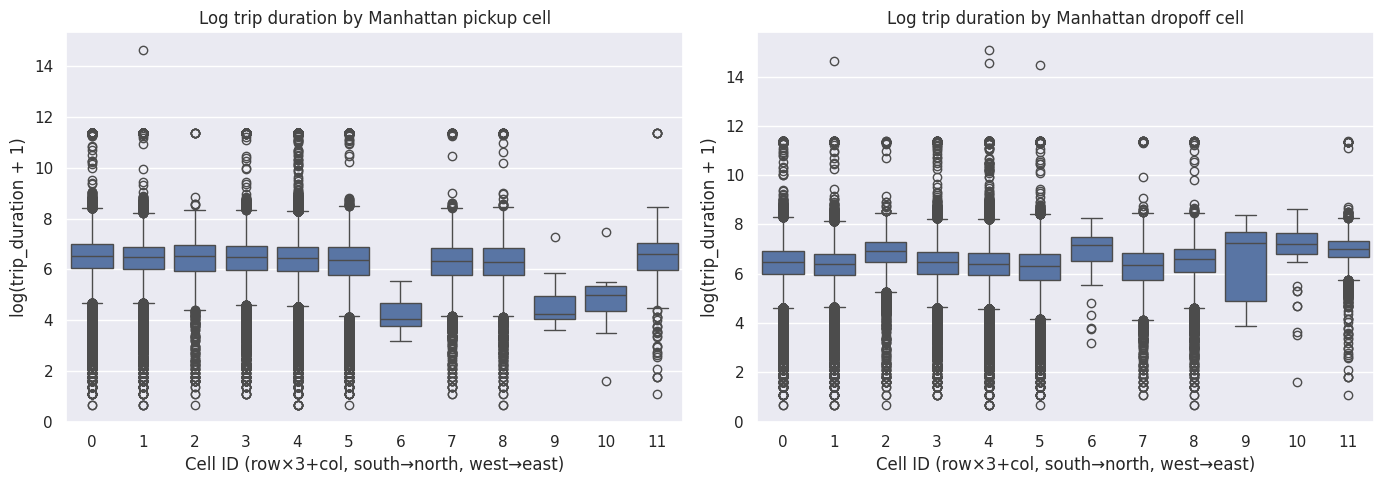

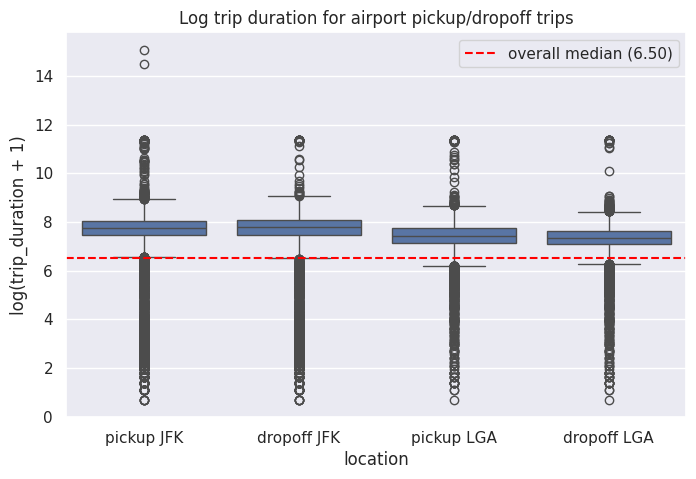

In [39]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -- Manhattan pickup cells --
man_pickup_cols = [f"pickup_manhattan_{k}" for k in range(MAN_ROWS * MAN_COLS)]
pickup_records = []
for k, col in enumerate(man_pickup_cols):
    vals = train_df.loc[train_df[col] == 1, "log_trip_duration"]
    pickup_records.append(pd.DataFrame({"cell": k, "log_trip_duration": vals}))
pickup_data = pd.concat(pickup_records, ignore_index=True)

sns.boxplot(data=pickup_data, x="cell", y="log_trip_duration", ax=axes[0])
axes[0].set_title("Log trip duration by Manhattan pickup cell")
axes[0].set_xlabel("Cell ID (row×3+col, south→north, west→east)")
axes[0].set_ylabel("log(trip_duration + 1)")

# -- Manhattan dropoff cells --
man_dropoff_cols = [f"dropoff_manhattan_{k}" for k in range(MAN_ROWS * MAN_COLS)]
dropoff_records = []
for k, col in enumerate(man_dropoff_cols):
    vals = train_df.loc[train_df[col] == 1, "log_trip_duration"]
    dropoff_records.append(pd.DataFrame({"cell": k, "log_trip_duration": vals}))
dropoff_data = pd.concat(dropoff_records, ignore_index=True)

sns.boxplot(data=dropoff_data, x="cell", y="log_trip_duration", ax=axes[1])
axes[1].set_title("Log trip duration by Manhattan dropoff cell")
axes[1].set_xlabel("Cell ID (row×3+col, south→north, west→east)")
axes[1].set_ylabel("log(trip_duration + 1)")

plt.tight_layout()
plt.show()

# -- Airport features --
airport_records = []
for col, label in [("pickup_jfk", "pickup JFK"), ("dropoff_jfk", "dropoff JFK"),
                   ("pickup_lga", "pickup LGA"), ("dropoff_lga", "dropoff LGA")]:
    vals = train_df.loc[train_df[col] == 1, "log_trip_duration"]
    airport_records.append(pd.DataFrame({"location": label, "log_trip_duration": vals}))
airport_data = pd.concat(airport_records, ignore_index=True)

plt.figure(figsize=(8, 5))
sns.boxplot(data=airport_data, x="location", y="log_trip_duration")
# baseline: overall distribution
overall_median = train_df["log_trip_duration"].median()
plt.axhline(overall_median, color="red", linestyle="--", label=f"overall median ({overall_median:.2f})")
plt.legend()
plt.title("Log trip duration for airport pickup/dropoff trips")
plt.ylabel("log(trip_duration + 1)")
plt.show()


**Question**: using these plots are the constructed features good?

They are not very good since most of the location points have similar distributions. The features don't help us determine log duration

<img src="https://www.dropbox.com/s/xson9nukz5hba7c/map.png?raw=1" align="right" width="20%" style="margin-left: 20px; margin-bottom: 20px">

**Task 9 (1 pts)**. To the current moment we almost didn't used the coordinates themselves. There are several reasons for this. First, the coordinates longtitute and latitude should be considered together and, second, the dependence between target and coordinates is not linear. In order to use coordinates somehow, we may use the following trick: find a geographic rectangle with the most number of rides (as on the figure) and then split this rectangle into ceparate cells. Let's assign a separate number to each of the cell and -1 to out-of-cell coordinates.

Write a transformer that first split the region into cells and then create two features: cell id for trip start and cell id for trip end. Choose number of rows and columns by yourself.

Please pay attention that all computations should be vectorized. The transformer should not modify the given dataset inplace, and all necessary statistics should be computed using the training set in `fit` procedure.

In [40]:
from sklearn.base import BaseEstimator, TransformerMixin

# Hardcoded airport bounding boxes
AIRPORTS = {
    "JFK": {"lat": (40.620, 40.660), "lon": (-73.820, -73.750)},
    "LGA": {"lat": (40.765, 40.790), "lon": (-73.890, -73.855)},
}

class MapGridTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, rows=4, cols=3, quantile=0.05):
        self.rows = rows
        self.cols = cols
        self.quantile = quantile  # lower tail; upper tail = 1 - quantile

    def fit(self, X, y=None):
        # Use both pickup and dropoff coords to learn the bounding box
        all_lat = pd.concat([X["pickup_latitude"], X["dropoff_latitude"]])
        all_lon = pd.concat([X["pickup_longitude"], X["dropoff_longitude"]])

        self.lat_min_ = all_lat.quantile(self.quantile)
        self.lat_max_ = all_lat.quantile(1 - self.quantile)
        self.lon_min_ = all_lon.quantile(self.quantile)
        self.lon_max_ = all_lon.quantile(1 - self.quantile)

        # Airport IDs follow the grid cells
        self.airport_ids_ = {
            name: self.rows * self.cols + i
            for i, name in enumerate(AIRPORTS)
        }
        return self

    def _assign_cell(self, lat, lon):
        """Assign a cell ID to each (lat, lon) pair. Vectorized."""
        n_grid_cells = self.rows * self.cols
        result = np.full(len(lat), -1, dtype=int)

        # --- Grid cells (inside quantile bounding box) ---
        in_box = (
            (lat >= self.lat_min_) & (lat <= self.lat_max_) &
            (lon >= self.lon_min_) & (lon <= self.lon_max_)
        )
        row_idx = ((lat - self.lat_min_) / (self.lat_max_ - self.lat_min_) * self.rows).astype(int).clip(0, self.rows - 1)
        col_idx = ((lon - self.lon_min_) / (self.lon_max_ - self.lon_min_) * self.cols).astype(int).clip(0, self.cols - 1)
        result[in_box] = (row_idx * self.cols + col_idx)[in_box]

        # --- Airports (override -1 even if outside the grid box) ---
        for name, bounds in AIRPORTS.items():
            in_airport = (
                (lat >= bounds["lat"][0]) & (lat <= bounds["lat"][1]) &
                (lon >= bounds["lon"][0]) & (lon <= bounds["lon"][1])
            )
            result[in_airport] = self.airport_ids_[name]

        return result

    def transform(self, X, y=None):
        lat_pu = X["pickup_latitude"].to_numpy()
        lon_pu = X["pickup_longitude"].to_numpy()
        lat_do = X["dropoff_latitude"].to_numpy()
        lon_do = X["dropoff_longitude"].to_numpy()

        # Assign directly — no copy, avoids doubling memory usage
        X["pickup_cell_id"]  = self._assign_cell(lat_pu, lon_pu)
        X["dropoff_cell_id"] = self._assign_cell(lat_do, lon_do)
        return X

    def show_map(self):
        """Visualize the grid and airport boxes on a folium map."""
        center_lat = (self.lat_min_ + self.lat_max_) / 2
        center_lon = (self.lon_min_ + self.lon_max_) / 2
        m = folium.Map(location=(center_lat, center_lon), zoom_start=12)

        # Draw grid cells
        lat_step = (self.lat_max_ - self.lat_min_) / self.rows
        lon_step = (self.lon_max_ - self.lon_min_) / self.cols
        for r in range(self.rows):
            for c in range(self.cols):
                cell_id = r * self.cols + c
                sw = (self.lat_min_ + r * lat_step,       self.lon_min_ + c * lon_step)
                ne = (self.lat_min_ + (r+1) * lat_step,   self.lon_min_ + (c+1) * lon_step)
                folium.Rectangle(
                    bounds=[sw, ne],
                    color="blue", fill=True, fill_opacity=0.1,
                    tooltip=f"Cell {cell_id} (row={r}, col={c})"
                ).add_to(m)

        # Draw airports
        for name, bounds in AIRPORTS.items():
            airport_id = self.airport_ids_[name]
            sw = (bounds["lat"][0], bounds["lon"][0])
            ne = (bounds["lat"][1], bounds["lon"][1])
            folium.Rectangle(
                bounds=[sw, ne],
                color="red", fill=True, fill_opacity=0.2,
                tooltip=f"{name} (cell {airport_id})"
            ).add_to(m)

        return m


# --- Fit on training data, then transform both sets ---
grid_transformer = MapGridTransformer(rows=4, cols=3, quantile=0.05)
grid_transformer.fit(train_df)

train_df = grid_transformer.transform(train_df)
test_df  = grid_transformer.transform(test_df)

# Sanity check
print(f"Bounding box learned from training data:")
print(f"  lat: [{grid_transformer.lat_min_:.4f}, {grid_transformer.lat_max_:.4f}]")
print(f"  lon: [{grid_transformer.lon_min_:.4f}, {grid_transformer.lon_max_:.4f}]")
print(f"\nCell ID mapping:  grid 0–11, JFK={grid_transformer.airport_ids_['JFK']}, LGA={grid_transformer.airport_ids_['LGA']}")
print(f"\nPickup cell distribution (train):")
print(train_df["pickup_cell_id"].value_counts().sort_index())

# Visualize
grid_transformer.show_map()


Bounding box learned from training data:
  lat: [40.7048, 40.7926]
  lon: [-74.0072, -73.9174]

Cell ID mapping:  grid 0–11, JFK=12, LGA=13

Pickup cell distribution (train):
pickup_cell_id
-1     102802
 0      75403
 1       4516
 2        903
 3     227688
 4      15622
 5       1813
 6     208847
 7     163942
 8       4142
 9      43973
 10    113573
 11      9577
 12     22333
 13     25916
Name: count, dtype: int64


**Task 10 (0.25 pts)**. Fit `Ridge`-regression with default parameters using features we have constructed to the current moment. Use one-hot-encoding for cathegorical features and scaling/normalization for numerical features.

In [42]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# Time features
cat_features = ["weekday", "month", "day_of_year"]
num_features = ["hour_sin", "hour_cos", "is_anom_jan", "is_anom_may", "log_haversine"]

# Position features — cell IDs as categorical
cat_features += ["pickup_cell_id", "dropoff_cell_id"]

# Manhattan grid binary columns (already binary → numerical)
num_features += [f"pickup_manhattan_{k}"  for k in range(MAN_ROWS * MAN_COLS)]
num_features += [f"dropoff_manhattan_{k}" for k in range(MAN_ROWS * MAN_COLS)]

# Airport binary features (already binary → numerical)
num_features += ["pickup_jfk", "dropoff_jfk", "pickup_lga", "dropoff_lga"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("num", StandardScaler(), num_features),
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("ridge", Ridge()),
])

X_train = train_df[cat_features + num_features]
y_train = train_df["log_trip_duration"]
X_test  = test_df[cat_features + num_features]
y_test  = test_df["log_trip_duration"]

model.fit(X_train, y_train)

train_rmsle = mean_squared_error(y_train, model.predict(X_train)) ** 0.5
test_rmsle  = mean_squared_error(y_test,  model.predict(X_test))  ** 0.5

print(f"Train RMSLE: {train_rmsle:.4f}")
print(f"Test  RMSLE: {test_rmsle:.4f}")


Train RMSLE: 0.4779
Test  RMSLE: 0.4776


## Part 3. Analyzing the remaining features (1 pts)

**Task 11 (0.75 pts)**. We have three features that were not analyzed to the current moment: `vendor_id`, `passenger_count` and `store_and_fwd_flag`.

**Question**: Think on why each of these features may be useful.

The amount of passengers could increase the number of stops, or maybe it could correlate with whether a ride is for business or leisure. If a certain vendor have taxis significantly faster then this would contribute to the model. I don't think the connectivity conditions of the measurement has any relevant impact on the data.

Count the number of unique values for each of these features:

In [44]:
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag"]:
      print(f"{col}: {df[col].nunique()} unique values — {df[col].unique()}")#Your code here

vendor_id: 2 unique values — [2 1]
passenger_count: 10 unique values — [1 6 4 2 3 5 0 7 9 8]
store_and_fwd_flag: 2 unique values — <StringArray>
['N', 'Y']
Length: 2, dtype: str


Construct boxplots for distributions of log trip duration and each of these features.

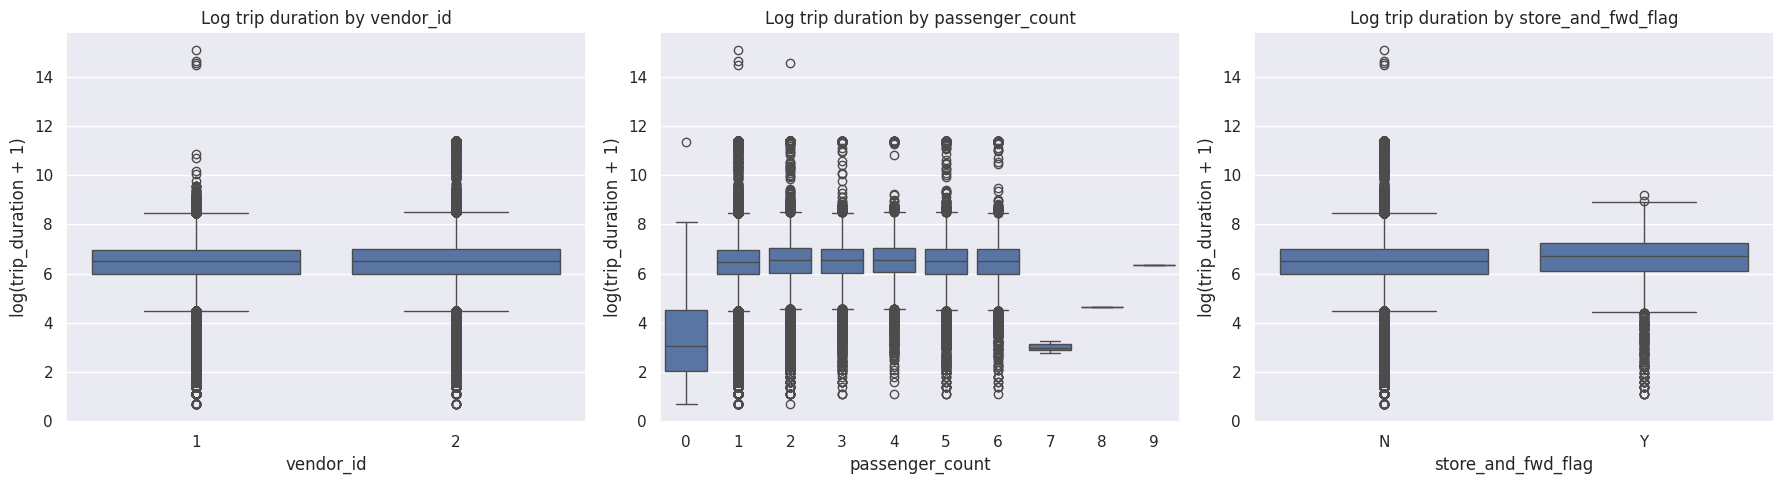

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["vendor_id", "passenger_count", "store_and_fwd_flag"]):
    records = []
    for val in sorted(df[col].unique()):
        vals = df.loc[df[col] == val, "log_trip_duration"]
        records.append(pd.DataFrame({col: val, "log_trip_duration": vals}))
    data = pd.concat(records, ignore_index=True)

    sns.boxplot(data=data, x=col, y="log_trip_duration", ax=ax)
    ax.set_title(f"Log trip duration by {col}")
    ax.set_ylabel("log(trip_duration + 1)")

plt.tight_layout()
plt.show()


Transform the features `vendor_id` and `store_and_fwd_flag` into values $\{0;1\}$

In [49]:
train_df["vendor_id"]         = (train_df["vendor_id"] == 2).astype(int)
test_df["vendor_id"]          = (test_df["vendor_id"] == 2).astype(int)

train_df["store_and_fwd_flag"] = (train_df["store_and_fwd_flag"] == "Y").astype(int)
test_df["store_and_fwd_flag"]  = (test_df["store_and_fwd_flag"] == "Y").astype(int)


**Question**: Based on the plots above what is your opinion on the prediction quality of these features?

it will be really low quality there is almost no difference between the distributions, and there feature values that only outliers fit

**Task 12 (0.25 pts)**. Check your considerations by training model on these threee features as well. Train `Ridge`-regression with standard parameters. Encode cathegorical features with one-hot-encoding and normalize the numerical ones.

In [54]:
#Your code h
#
cat_features_p3 = cat_features + ["passenger_count"]
num_features_p3 = num_features + ["vendor_id", "store_and_fwd_flag"]

preprocessor_p3 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features_p3),
    ("num", StandardScaler(), num_features_p3),
])

model_p3 = Pipeline([
    ("preprocessor", preprocessor_p3),
    ("ridge", Ridge()),
])

X_train_p3 = train_df[cat_features_p3 + num_features_p3]
X_test_p3  = test_df[cat_features_p3 + num_features_p3]

model_p3.fit(X_train_p3, y_train)

train_rmsle = mean_squared_error(y_train, model_p3.predict(X_train_p3)) ** 0.5
test_rmsle  = mean_squared_error(y_test,  model_p3.predict(X_test_p3))  ** 0.5

print(f"Train RMSLE: {train_rmsle:.4f}")
print(f"Test  RMSLE: {test_rmsle:.4f}")

Train RMSLE: 0.4775
Test  RMSLE: 0.4771


If the features do not give any sufficient impact to the prediction quality then delete them from the data.

In [55]:
train_df = train_df.drop(columns=["vendor_id", "passenger_count", "store_and_fwd_flag"])
test_df  = test_df.drop(columns=["vendor_id", "passenger_count", "store_and_fwd_flag"])


## Part 4. Improving the model (3 pts)

**Task 13 (1 pts)**. In the training data we have non-typical objects (outliers): objects with anomalous small trip duration, with very high covered distance or big remainders of the regression model. In this task the goal is to exclude such objects from the training set. For this reason plot histograms of mentioned values, choose outlier objects and exclude them from the training set.

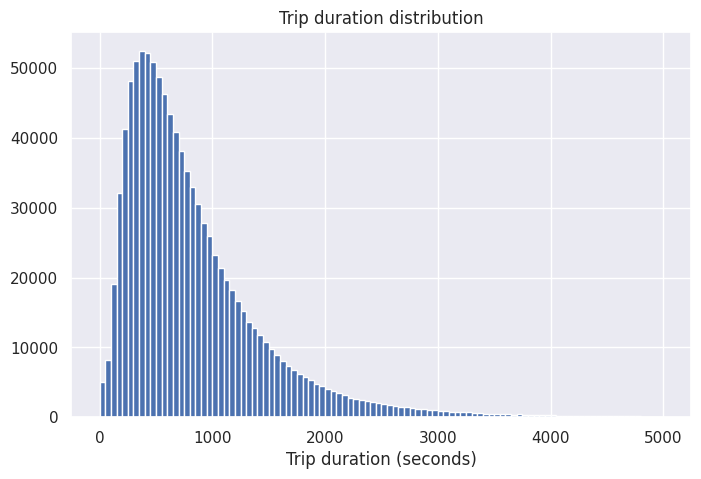

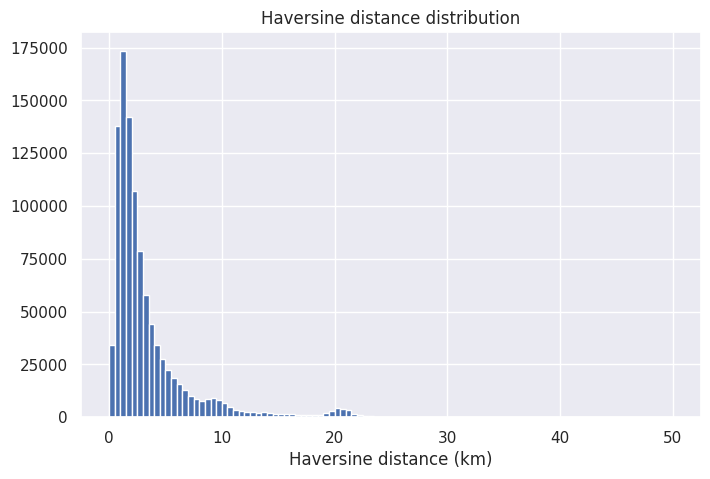

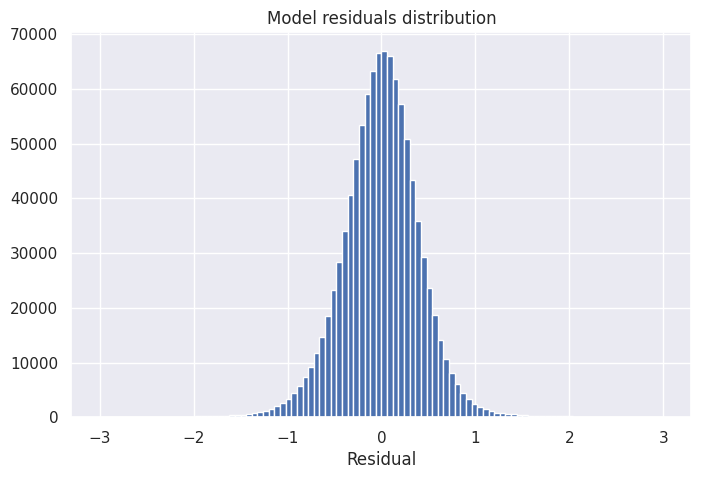

In [60]:
X_train = train_df[cat_features + num_features]
X_test  = test_df[cat_features + num_features]

model.fit(X_train, y_train)

residuals = y_train - model.predict(X_train)

plt.figure(figsize=(8, 5))
plt.hist(train_df["trip_duration"], bins=100, range=(0, 5000))
plt.xlabel("Trip duration (seconds)")
plt.title("Trip duration distribution")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(train_df["haversine"], bins=100, range=(0, 50))
plt.xlabel("Haversine distance (km)")
plt.title("Haversine distance distribution")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=100, range=(-3, 3))
plt.xlabel("Residual")
plt.title("Model residuals distribution")
plt.show()


In [61]:
dur_low,  dur_high  = train_df["trip_duration"].quantile(0.01), train_df["trip_duration"].quantile(0.99)
hav_low,  hav_high  = train_df["haversine"].quantile(0.01),     train_df["haversine"].quantile(0.99)

mask = (
    (train_df["trip_duration"] >= dur_low)  & (train_df["trip_duration"] <= dur_high) &
    (train_df["haversine"]     >= hav_low)  & (train_df["haversine"]     <= hav_high) &
    (residuals >= -1.8) & (residuals <= 1.8)
)

train_df = train_df[mask]
y_train  = y_train[mask]

print(f"Removed {(~mask).sum()} outliers — {len(train_df)} rows remaining")


Removed 33371 outliers — 987679 rows remaining


Currently we have many cathegorical features. Some cathegories are very rare and contain only few objects. The presence of such rare cathegories may lead to model overfitting. For each of the presented cathegorical features find rare cathegories (if there are any) and unite them into one bigger cathegory.

In [ ]:
train_df = train_df.drop(columns=["day_of_year"])
test_df  = test_df.drop(columns=["day_of_year"])
cat_features.remove("day_of_year")

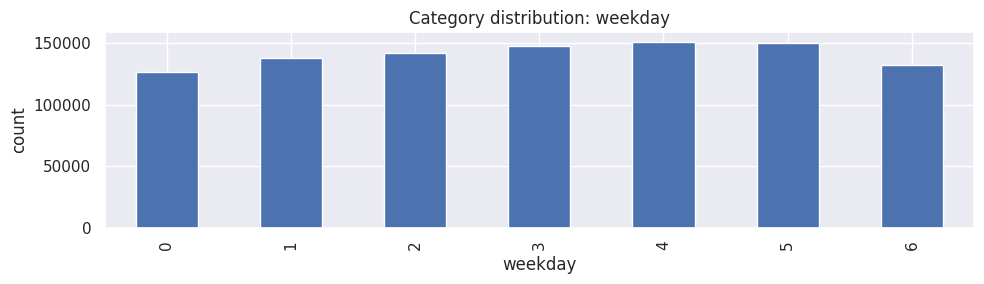

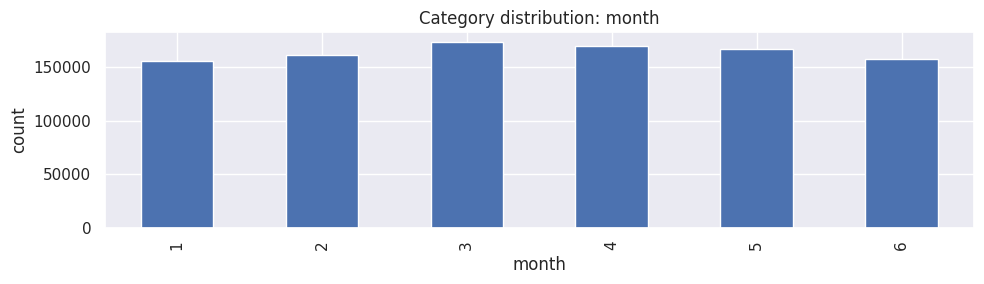

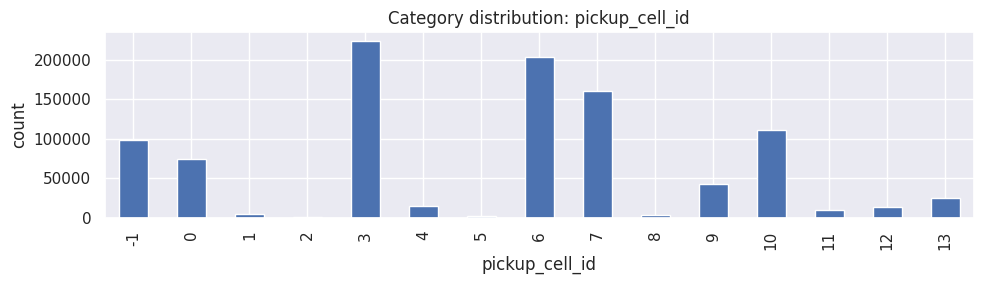

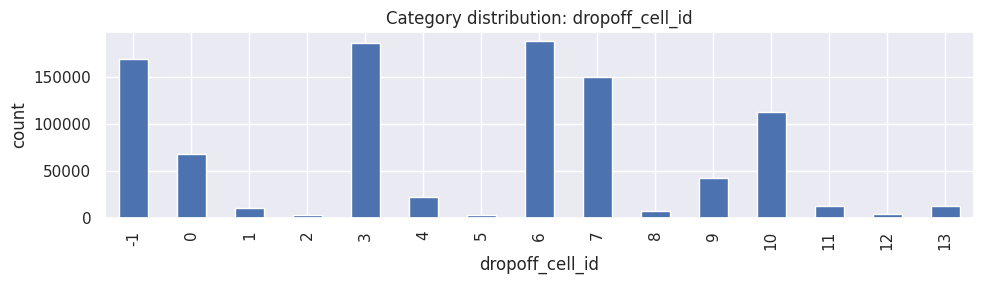

In [68]:
#Your code
for col in cat_features:
    plt.figure(figsize=(10, 3))
    train_df[col].value_counts().sort_index().plot(kind="bar")
    plt.title(f"Category distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("count")
    plt.tight_layout()
    plt.show()


In [69]:
rare_other  = {2, 5, 8}
rare_merged = {1, 11, 12, 13}

for df_ in [train_df, test_df]:
    for col in ["pickup_cell_id", "dropoff_cell_id"]:
        df_[col] = df_[col].apply(lambda x: -1 if x in rare_other else (20 if x in rare_merged else x))

Fit the model on the cleaned dataset and compute the quality of the test set.

In [70]:
X_train = train_df[cat_features + num_features]
X_test  = test_df[cat_features + num_features]

model.fit(X_train, y_train)

train_rmsle = mean_squared_error(y_train, model.predict(X_train)) ** 0.5
test_rmsle  = mean_squared_error(y_test,  model.predict(X_test))  ** 0.5

print(f"Train RMSLE: {train_rmsle:.4f}")
print(f"Test  RMSLE: {test_rmsle:.4f}")


Train RMSLE: 0.3887
Test  RMSLE: 0.4805


**Task 14 (1 pts)**. After one-hot-enconding the number of features in the dataset is sufficiently increasing. Compute the number of features before and after encoding of cathegorical features.

In [73]:
before = len(cat_features + num_features)

ohe = model.named_steps["preprocessor"].named_transformers_["cat"]
after_cat = len(ohe.get_feature_names_out())
after = after_cat + len(num_features)

print(f"Features before encoding: {before}")
print(f"Features after encoding:  {after}  ({after_cat} from OHE + {len(num_features)} numerical)")

Features before encoding: 37
Features after encoding:  64  (31 from OHE + 33 numerical)


Try train not `Ridge`-, but `Lasso`-regression. Which of these two methods is better?

In [74]:
from sklearn.linear_model import Lasso

model_lasso = Pipeline([
    ("preprocessor", preprocessor),
    ("lasso", Lasso()),
])

model_lasso.fit(X_train, y_train)

train_rmsle = mean_squared_error(y_train, model_lasso.predict(X_train)) ** 0.5
test_rmsle  = mean_squared_error(y_test,  model_lasso.predict(X_test))  ** 0.5

print(f"Lasso Train RMSLE: {train_rmsle:.4f}")
print(f"Lasso Test  RMSLE: {test_rmsle:.4f}")
#Your code here

Lasso Train RMSLE: 0.6901
Lasso Test  RMSLE: 0.7950


Split _training set_ into training and validation part in 8:2 ratio. Using validation part find optimal value of regularization coefficient (using logarithmic grid) for `Ridge` and `Lasso`. Estimate the quality of the best model on test set.

In [78]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

alphas = np.logspace(-3, 3, 10)

best_ridge = {"alpha": None, "rmsle": np.inf}
best_lasso = {"alpha": None, "rmsle": np.inf}

for alpha in alphas:
    for name, Reg, best in [("ridge", Ridge, best_ridge), ("lasso", Lasso, best_lasso)]:
        m = Pipeline([("preprocessor", preprocessor), (name, Reg(alpha=alpha))])
        m.fit(X_tr, y_tr)
        rmsle = mean_squared_error(y_val, m.predict(X_val)) ** 0.5
        if rmsle < best["rmsle"]:
            best["rmsle"] = rmsle
            best["alpha"] = alpha

print(f"Best Ridge alpha: {best_ridge['alpha']:.5f}  —  val RMSLE: {best_ridge['rmsle']:.4f}")
print(f"Best Lasso alpha: {best_lasso['alpha']:.5f}  —  val RMSLE: {best_lasso['rmsle']:.4f}")

# Retrain best models on full training set and evaluate on test
for name, Reg, best in [("Ridge", Ridge, best_ridge), ("Lasso", Lasso, best_lasso)]:
    m = Pipeline([("preprocessor", preprocessor), (name.lower(), Reg(alpha=best["alpha"]))])
    m.fit(X_train, y_train)
    test_rmsle = mean_squared_error(y_test, m.predict(X_test)) ** 0.5
    print(f"{name} (alpha={best['alpha']:.5f})  —  test RMSLE: {test_rmsle:.4f}")


Best Ridge alpha: 215.44347  —  val RMSLE: 0.3885
Best Lasso alpha: 0.00100  —  val RMSLE: 0.3889
Ridge (alpha=215.44347)  —  test RMSLE: 0.4805
Lasso (alpha=0.00100)  —  test RMSLE: 0.4809


For each of regularization parameter `alpha` in Lasso-regression find number of non-zero weights and plot these values w.r.t. `alpha`. What would be a degradation of performance in case of using only one half of features?

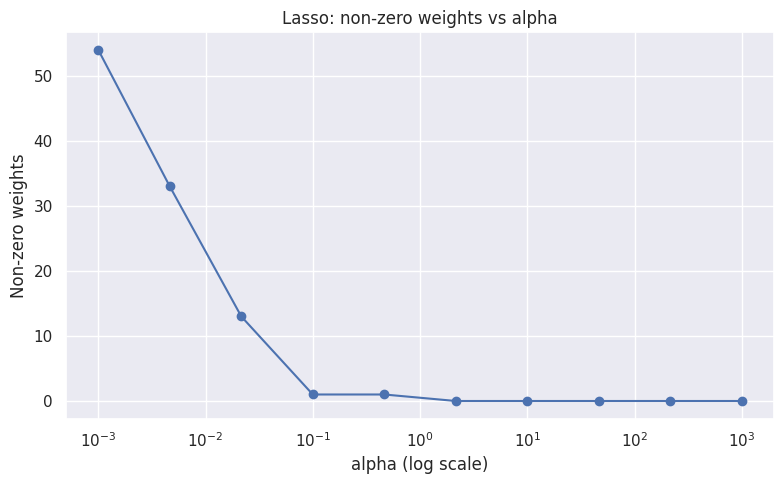

Total features: 64
Alpha giving ~half features (33): 0.00464
Test RMSLE with half features: 0.4856


In [79]:
nonzero_counts = []

for alpha in alphas:
    m = Pipeline([("preprocessor", preprocessor), ("lasso", Lasso(alpha=alpha))])
    m.fit(X_tr, y_tr)
    nonzero = np.sum(m.named_steps["lasso"].coef_ != 0)
    nonzero_counts.append(nonzero)

plt.figure(figsize=(8, 5))
plt.plot(alphas, nonzero_counts, marker="o")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("Non-zero weights")
plt.title("Lasso: non-zero weights vs alpha")
plt.tight_layout()
plt.show()

# Find alpha that gives ~half the features
total_features = len(m.named_steps["lasso"].coef_)
half = total_features // 2
idx = np.argmin(np.abs(np.array(nonzero_counts) - half))
alpha_half = alphas[idx]

m_half = Pipeline([("preprocessor", preprocessor), ("lasso", Lasso(alpha=alpha_half))])
m_half.fit(X_train, y_train)
test_rmsle_half = mean_squared_error(y_test, m_half.predict(X_test)) ** 0.5

print(f"Total features: {total_features}")
print(f"Alpha giving ~half features ({nonzero_counts[idx]}): {alpha_half:.5f}")
print(f"Test RMSLE with half features: {test_rmsle_half:.4f}")


<img src="https://www.dropbox.com/s/wp4jj0599np17lh/map_direction.png?raw=1" width="20%" align="right" style="margin-left: 20px">

**Task 15 (1 pts)**. It is often useful considering feature interactions and construct new features from original ones. Previously we have split the Manhatten map into cells and introduced the features of cell id start/finish.

Let's try the following: compute how often each pair (start cell id, end cell id) is occured in the training set and take 100 most often pairs. Encode these pairs as cathegorical feature and add -1 to the remaining situations.

**Question**: Why is this feature potentially useful? Why can't linear model find the corresponding information by itself regardless of the model's access to the information about start cell and end cell?

In [ ]:
#Your code here

Fit the model (`Ridge` or `Lasso` depending on previous observations) on the new features and compute the quality on the testing set.

In [ ]:
#Your code here